# 00b - EDA del dataset AIC anonimizzato

Strategia e obiettivi: [eda_strategy.md](eda_strategy.md).

Target: `sub_category` data la `macro_category` (già nota in input). Tutte le analisi sono fatte **per macro**.

Testo modello: `ocr_surrogates` (normalizzato in colonna `text`).

## Setup


In [ ]:
import hashlib
import json
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
    force=True,
)
logger = logging.getLogger(__name__)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Repo root (pyproject.toml) not found")
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

DATA_PATH = ROOT / "data" / "df_sample_all.parquet"
TEXT_COLUMN = "ocr_surrogates"
EDA_CACHE = ROOT / "data" / "eda_cache"
EDA_CACHE.mkdir(parents=True, exist_ok=True)
EDA_SUMMARY_DIR = EDA_CACHE / "eda_summary"
RUN_CONFIG_PATH = ROOT / "data" / "run_config.json"
SPLITS_PATH = ROOT / "data" / "splits_v1.parquet"

from slm_baseline.data import normalize_text
from slm_baseline.labels import MICRO_PER_MACRO, composite_label, is_in_perimeter

logger.info("ROOT=%s", ROOT)


## Caricamento del dataset

Parquet locale (`data/df_sample_all.parquet`). Non caricare colonne OCR non anonimizzate.


In [ ]:
EDA_COLUMNS = [
    "record_key",
    "document_id",
    "segment_id",
    "job_id",
    "created_at",
    "macro_category",
    "sub_category",
    "pages_list",
    "ocr_confidence",
    "ocr_surrogates",
    "ocr_num_words",
    "ocr_num_words_handwritten",
    "ocr_handwritten_rate",
]

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Missing dataset: {DATA_PATH}")

df = pd.read_parquet(DATA_PATH, columns=EDA_COLUMNS)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
df["created_date"] = df["created_at"].dt.normalize()
df["text"] = df[TEXT_COLUMN].map(normalize_text)

missing_labels = (df["macro_category"].fillna("").astype(str).str.strip() == "") | (
    df["sub_category"].fillna("").astype(str).str.strip() == ""
)
labeled_df = df[~missing_labels].copy()
n_days = labeled_df["created_date"].nunique()

display(
    pd.Series(
        {
            "segments": len(df),
            "segments without macro/sub": int(missing_labels.sum()),
            "empty text (surrogates)": int((labeled_df["text"].str.len() == 0).sum()),
            "documents": df["document_id"].nunique(),
            "jobs": df["job_id"].nunique(),
            "macro categories": labeled_df["macro_category"].nunique(),
            "macro/sub pairs": labeled_df.groupby(["macro_category", "sub_category"]).ngroups,
            "first day": df["created_date"].min().date(),
            "last day": df["created_date"].max().date(),
            "days with data": n_days,
            "mean segments per day": round(len(labeled_df) / n_days, 1),
        },
        name="value",
    ).to_frame()
)


## O1 - Copertura e bilanciamento delle sub per macro

### O1.1 - Controllo delle etichette


In [ ]:
macro_variants = labeled_df.groupby(
    labeled_df["macro_category"].str.strip().str.casefold().rename("normalized_macro")
)["macro_category"].unique()
macro_variants = macro_variants[macro_variants.map(len) > 1]

sub_variants = labeled_df.groupby(
    ["macro_category", labeled_df["sub_category"].str.strip().str.casefold().rename("normalized_sub")]
)["sub_category"].unique()
sub_variants = sub_variants[sub_variants.map(len) > 1]

macros_per_sub = labeled_df.groupby("sub_category")["macro_category"].unique()
shared_subs = macros_per_sub[macros_per_sub.map(len) > 1]

logger.info("Segments without macro/sub: %s", int(missing_labels.sum()))
logger.info("Macro with spelling variants: %s", len(macro_variants))
logger.info("Sub with spelling variants (same macro): %s", len(sub_variants))
logger.info("Sub used under more than one macro: %s", len(shared_subs))

if not macro_variants.empty:
    display(macro_variants.to_frame("variants"))
if not sub_variants.empty:
    display(sub_variants.to_frame("variants"))
if not shared_subs.empty:
    display(
        pd.crosstab(
            labeled_df.loc[labeled_df["sub_category"].isin(shared_subs.index), "sub_category"],
            labeled_df["macro_category"],
        )
    )


### O1.1b - Coerenza con la tassonomia ammessa

Perimetro da `slm_baseline.labels.MICRO_PER_MACRO`. Righe fuori perimetro escluse da `labeled_df`.


In [ ]:
in_perimeter = [is_in_perimeter(m, s) for m, s in zip(labeled_df["macro_category"], labeled_df["sub_category"])]
in_perimeter = np.array(in_perimeter, dtype=bool)
out_of_taxonomy = labeled_df[~in_perimeter]

logger.info(
    "Segments with sub not allowed for macro: %s (excluded)",
    len(out_of_taxonomy),
)
if len(out_of_taxonomy):
    display(
        out_of_taxonomy.groupby(
            ["macro_category", "sub_category", out_of_taxonomy["created_date"].dt.date.rename("day")]
        ).agg(segments=("record_key", "size"), documents=("document_id", "nunique"))
    )

labeled_df = labeled_df[in_perimeter].copy()
n_days = labeled_df["created_date"].nunique()
logger.info("Segments kept for EDA: %s", len(labeled_df))


### O1.2 - Volumi per macro

In [ ]:
segments_per_pair = labeled_df.groupby(["macro_category", "sub_category"]).size()

macro_summary = (
    labeled_df.groupby("macro_category")
    .agg(
        segments=("record_key", "size"),
        documents=("document_id", "nunique"),
        sub_categories=("sub_category", "nunique"),
    )
    .sort_values("segments", ascending=False)
)
macro_summary["share"] = (macro_summary["segments"] / macro_summary["segments"].sum()).round(3)
macro_summary["segments_per_day"] = (macro_summary["segments"] / n_days).round(1)
macro_summary["max_min_ratio"] = segments_per_pair.groupby(level="macro_category").agg(
    lambda s: s.max() / s.min()
).round(1)
macro_summary["single_sub"] = macro_summary["sub_categories"] == 1
macro_summary


### O1.3 - Copertura delle sub rispetto alle soglie

In [ ]:
MIN_DOCUMENTS_EDA = 20
MIN_SEGMENTS_TRAIN = 100
TARGET_SEGMENTS_TRAIN = 300

sub_summary = (
    labeled_df.groupby(["macro_category", "sub_category"])
    .agg(
        segments=("record_key", "size"),
        documents=("document_id", "nunique"),
        days_seen=("created_date", "nunique"),
    )
    .reset_index()
)
sub_summary["share_in_macro"] = (
    sub_summary["segments"] / sub_summary.groupby("macro_category")["segments"].transform("sum")
).round(3)

daily_rate = sub_summary["segments"] / n_days
sub_summary["segments_per_day"] = daily_rate.round(2)
sub_summary["days_to_target"] = np.ceil(
    (TARGET_SEGMENTS_TRAIN - sub_summary["segments"]).clip(lower=0) / daily_rate.replace(0, np.nan)
).astype("Int64")

single_sub_macros = macro_summary.index[macro_summary["single_sub"]]
sub_summary["status"] = np.select(
    [
        sub_summary["macro_category"].isin(single_sub_macros),
        sub_summary["documents"] < MIN_DOCUMENTS_EDA,
        sub_summary["segments"] < MIN_SEGMENTS_TRAIN,
        sub_summary["segments"] < TARGET_SEGMENTS_TRAIN,
    ],
    ["macro con una sola sub", "insufficiente", "solo EDA", "training (minimo)"],
    default="training (target)",
)
sub_summary = sub_summary.sort_values(["macro_category", "segments"], ascending=[True, False]).reset_index(
    drop=True
)

display(sub_summary)
display(pd.crosstab(sub_summary["macro_category"], sub_summary["status"], margins=True))


In [ ]:
for macro, group in sub_summary.groupby("macro_category"):
    group = group.sort_values("segments")
    fig, ax = plt.subplots(figsize=(10, 0.35 * len(group) + 1.5))
    ax.barh(group["sub_category"], group["segments"], color="tab:blue")
    ax.axvline(MIN_SEGMENTS_TRAIN, color="tab:orange", linestyle="--", label=f"min training ({MIN_SEGMENTS_TRAIN})")
    ax.axvline(TARGET_SEGMENTS_TRAIN, color="tab:green", linestyle="--", label=f"target ({TARGET_SEGMENTS_TRAIN})")
    ax.set_xscale("log")
    ax.set_xlabel("segments (log scale)")
    ax.set_title(f"{macro} - segments per sub ({group['segments'].sum()} total)")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()


### O1.4 - Volumi giornalieri

In [ ]:
daily = labeled_df.groupby(["created_date", "macro_category"]).size().unstack(fill_value=0).sort_index()

expected_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = expected_days.difference(daily.index)
logger.info(
    "Days without data in range: %s",
    len(missing_days),
)

daily = daily.reindex(expected_days, fill_value=0)
daily.index = daily.index.date

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
daily.plot.bar(stacked=True, ax=axes[0], width=0.9)
axes[0].set_title("Segments per day by macro (0 = missing run)")
daily.cumsum().plot(ax=axes[1], drawstyle="steps-post")
axes[1].set_title("Cumulative segments by macro")
for ax in axes:
    ax.set_xlabel("created_at (day, UTC)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

daily.loc[daily.sum(axis=1) > 0].sum(axis=1).describe().round(1).to_frame("segments per day (days with data)")


### O1.5 - Dimensionamento test per sub (documenti indipendenti)

Stima documenti di test per sub a recall attesa; non è un piano di raccolta futura.


In [ ]:
from statistics import NormalDist

TRAIN_SEGMENTS = 300
VALIDATION_SEGMENTS = 50
EXPECTED_RECALL = 0.95
CONFIDENCE_LEVEL = 0.98
TEST_MARGIN = 0.05
HORIZON_DAYS = 60

z_value = NormalDist().inv_cdf((1 + CONFIDENCE_LEVEL) / 2)
test_documents = int(np.ceil(z_value**2 * EXPECTED_RECALL * (1 - EXPECTED_RECALL) / TEST_MARGIN**2))

collection_plan = labeled_df.groupby(["macro_category", "sub_category"]).agg(
    segments=("record_key", "size"),
    documents=("document_id", "nunique"),
)
segments_per_document = collection_plan["segments"] / collection_plan["documents"]
collection_plan["segments_per_document"] = segments_per_document.round(2)
collection_plan["segments_needed"] = (
    TRAIN_SEGMENTS + VALIDATION_SEGMENTS + np.ceil(test_documents * segments_per_document)
).astype(int)
collection_plan["missing_segments"] = (collection_plan["segments_needed"] - collection_plan["segments"]).clip(lower=0)
collection_plan["surplus_segments"] = (collection_plan["segments"] - collection_plan["segments_needed"]).clip(lower=0)

rate = labeled_df.groupby(["macro_category", "sub_category"]).size().reindex(collection_plan.index, fill_value=0) / n_days
collection_plan["segments_per_day"] = rate.round(1)
days_to_ready = np.ceil(collection_plan["missing_segments"] / rate.replace(0, np.nan)).replace(np.inf, np.nan)
collection_plan["days_to_ready"] = days_to_ready.where(collection_plan["missing_segments"] > 0, 0)

logger.info(
    "Test documents per sub: %s (recall %s, margin ±%s)",
    test_documents,
    EXPECTED_RECALL,
    TEST_MARGIN,
)
logger.info(
    "Subs needing more than %s days at current rate: %s",
    HORIZON_DAYS,
    int((collection_plan["days_to_ready"] > HORIZON_DAYS).sum()),
)

collection_plan.sort_values(["macro_category", "days_to_ready"], ascending=[True, False])


### O1 - Decisioni (auto da tabelle sopra)

In [ ]:
rare_subs = sub_summary[sub_summary["segments"] < MIN_SEGMENTS_TRAIN][
    ["macro_category", "sub_category", "segments", "status"]
]
print("Sub sotto MIN_SEGMENTS_TRAIN:")
display(rare_subs)
print("Macro escluse (single sub):", list(single_sub_macros))
print("Righe fuori tassonomia escluse:", len(out_of_taxonomy))


## O2 - Qualità del testo in ingresso

### O2.1 - Lunghezza del testo e segmenti corti


In [ ]:
MIN_WORDS = 20

labeled_df["n_words"] = labeled_df["text"].str.split().str.len()
labeled_df["n_pages"] = labeled_df["pages_list"].str.len()
labeled_df["is_short"] = labeled_df["n_words"] < MIN_WORDS
labeled_df["empty_text"] = labeled_df["text"].str.len() == 0

length_summary = (
    labeled_df.groupby(["macro_category", "sub_category"])
    .agg(
        segments=("record_key", "size"),
        empty_share=("empty_text", "mean"),
        pages_p50=("n_pages", "median"),
        pages_max=("n_pages", "max"),
        words_p50=("n_words", "median"),
        words_p95=("n_words", lambda s: s.quantile(0.95)),
        short_share=("is_short", "mean"),
    )
    .round(3)
)

logger.info(
    "Empty text: %s (%.1f%%) | under %s words: %s (%.1f%%)",
    int(labeled_df["empty_text"].sum()),
    100 * labeled_df["empty_text"].mean(),
    MIN_WORDS,
    int(labeled_df["is_short"].sum()),
    100 * labeled_df["is_short"].mean(),
)
display(length_summary.head(30))


### O2.2 - Qualità OCR e scrittura a mano

In [ ]:
LOW_CONFIDENCE = 0.80
HIGH_HANDWRITTEN = 0.50

display(labeled_df[["ocr_confidence", "ocr_handwritten_rate"]].describe().round(3))

confidence_scale = 100 if labeled_df["ocr_confidence"].max() > 1 else 1
labeled_df["low_confidence"] = labeled_df["ocr_confidence"] < LOW_CONFIDENCE * confidence_scale
labeled_df["mostly_handwritten"] = labeled_df["ocr_handwritten_rate"] > HIGH_HANDWRITTEN

quality_summary = (
    labeled_df.groupby(["macro_category", "sub_category"])
    .agg(
        segments=("record_key", "size"),
        missing_ocr_stats=("ocr_confidence", lambda s: s.isna().mean()),
        confidence_p50=("ocr_confidence", "median"),
        low_confidence_share=("low_confidence", "mean"),
        handwritten_p50=("ocr_handwritten_rate", "median"),
        mostly_handwritten_share=("mostly_handwritten", "mean"),
    )
    .round(3)
)
display(quality_summary.head(20))


### O2.3 - Lunghezza in token (prompt v1, tre tokenizer)

Campione stratificato per macro (max `TOKEN_SCAN_MAX_ROWS`) per tempi accettabili in locale.
Il valore definitivo di `max_seq_length` va ricalcolato sul dataset completo in `00_prepare_data_and_splits.ipynb`.


In [ ]:
from transformers import AutoTokenizer

from slm_baseline.inference import recommend_max_seq_len, token_length_report

MODEL_IDS = [
    "Qwen/Qwen3-1.7B",
    "HuggingFaceTB/SmolLM3-3B",
    "google/gemma-3-4b-it",
]
TOKEN_SCAN_MAX_ROWS = 8000
CANDIDATE_MAX_SEQ_LENGTHS = (4096, 8192, 16384, 32768)

eda_df = labeled_df[~labeled_df["empty_text"]].copy()
if len(eda_df) > TOKEN_SCAN_MAX_ROWS:
    n_macros = eda_df["macro_category"].nunique()
    per_macro = max(1, TOKEN_SCAN_MAX_ROWS // n_macros)
    eda_parts = [
        g.sample(n=min(len(g), per_macro), random_state=42)
        for _, g in eda_df.groupby("macro_category", sort=False)
    ]
    eda_df = pd.concat(eda_parts)
logger.info("Token scan on %s segments", len(eda_df))
required_cols = {"macro_category", "sub_category", "text", "record_key"}
missing = required_cols - set(eda_df.columns)
if missing:
    raise KeyError(f"eda_df missing columns {missing} — check stratified sampling")

lengths_by_model: dict[str, pd.Series] = {}
coverage_tables = {}
for model_id in MODEL_IDS:
    logger.info("Tokenizer: %s", model_id)
    try:
        tok = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
    except Exception as exc:
        logger.warning("Skip tokenizer %s: %s", model_id, exc)
        continue
    lengths, cov = token_length_report(tok, eda_df, thresholds=CANDIDATE_MAX_SEQ_LENGTHS)
    lengths_by_model[model_id] = lengths
    cov["model"] = model_id
    coverage_tables[model_id] = cov
    display(cov)

if not lengths_by_model:
    raise RuntimeError("No tokenizers loaded — check HF access for Gemma/Qwen/SmolLM3")

recommended = recommend_max_seq_len(lengths_by_model, headroom=0.20, multiple=1024)
logger.info("Recommended max_seq_length (sample): %s", recommended)
if RUN_CONFIG_PATH.is_file():
    with open(RUN_CONFIG_PATH) as f:
        run_cfg = json.load(f)
    logger.info("run_config.json max_seq_len: %s", run_cfg.get("max_seq_len"))


### O2.4 - Impatto aggregato dei filtri di qualità

In [ ]:
SELECTED_MAX_SEQ_LENGTH = recommend_max_seq_len(lengths_by_model, headroom=0.20, multiple=1024)

labeled_df["too_long"] = False
if "Qwen/Qwen3-1.7B" in lengths_by_model:
    q_len = lengths_by_model["Qwen/Qwen3-1.7B"]
    labeled_df.loc[eda_df.index, "too_long"] = q_len.reindex(eda_df.index).values > SELECTED_MAX_SEQ_LENGTH
quality_flags = ["is_short", "low_confidence", "mostly_handwritten", "empty_text", "too_long"]
labeled_df["any_flag"] = labeled_df[quality_flags].any(axis=1)

flag_summary = labeled_df.groupby(["macro_category", "sub_category"])[quality_flags + ["any_flag"]].mean().round(3)
flag_summary.insert(0, "segments", labeled_df.groupby(["macro_category", "sub_category"]).size())
display(flag_summary.head(25))
logger.info("Share flagged overall: %s", labeled_df[quality_flags + ["any_flag"]].mean().round(3).to_dict())


### O2 - Decisioni (auto)

In [ ]:
print(f"SELECTED_MAX_SEQ_LENGTH (EDA sample): {SELECTED_MAX_SEQ_LENGTH}")
print(f"Empty text segments to exclude from eval: {int(labeled_df['empty_text'].sum())}")
biased = flag_summary[flag_summary["any_flag"] > 0.5]
print("Sub with >50% any_flag (review filters):")
display(biased.head(15))


## O3 - Segnali discriminanti nei surrogati

Senza testo originale non misuriamo la perdita dell'anonimizzazione; controlliamo se restano pattern utili per sub.


In [ ]:
import re

SIGNAL_PATTERNS: dict[str, list[tuple[str, str]]] = {
    "documento_di_spesa": [
        ("iva", r"\biva\b|imposta"),
        ("importo_euro", r"€|eur\b|totale"),
        ("scontrino_kw", r"scontrino|corrispettiv"),
        ("fattura_kw", r"fattura|fatt\.?\s*n"),
        ("ricevuta_kw", r"ricevuta|pagamento"),
        ("preventivo_kw", r"preventivo|stima"),
    ],
    "documento_di_spesa_medica": [
        ("ticket_ssn", r"ticket|ssn|servizio sanitario|tesser"),
        ("fattura_kw", r"fattura"),
        ("importo_euro", r"€|eur\b"),
    ],
    "documentazione_medica": [
        ("pronto_soccorso", r"pronto\s*soccorso|ps\b|emergenz"),
        ("dimissioni", r"dimission|reparto"),
        ("prescrizione", r"prescriz|farmaco|ricetta"),
        ("certificato", r"certificat|guarigion"),
    ],
    "denuncia": [
        ("cai", r"\bcai\b|constatazione|modulo\s*blu"),
        ("danni", r"dann|risarciment|sinistro"),
    ],
}

signal_rows = []
for macro, patterns in SIGNAL_PATTERNS.items():
    sub_df = labeled_df[(labeled_df["macro_category"] == macro) & (~labeled_df["empty_text"])]
    if sub_df.empty:
        continue
    for sub, grp in sub_df.groupby("sub_category"):
        text_l = grp["text"].str.lower()
        row = {"macro_category": macro, "sub_category": sub, "segments": len(grp)}
        for name, pat in patterns:
            row[f"hit_{name}"] = text_l.str.contains(pat, regex=True, na=False).mean()
        signal_rows.append(row)

signal_df = pd.DataFrame(signal_rows).round(3)
display(signal_df.sort_values(["macro_category", "sub_category"]))


In [ ]:
def compute_o6_leakage_stats(labeled_df: pd.DataFrame, splits_path: Path) -> dict:
    from slm_baseline.data import check_no_group_leakage

    segs_per_doc = labeled_df.groupby("document_id").size()
    macros_per_doc = labeled_df.groupby("document_id")["macro_category"].nunique()

    splits_rows = None
    splits_leakage_ok = None
    if splits_path.is_file():
        splits = pd.read_parquet(splits_path)
        splits_rows = int(len(splits))
        try:
            check_no_group_leakage(splits)
            splits_leakage_ok = True
        except AssertionError:
            splits_leakage_ok = False

    if "text_hash" not in labeled_df.columns:
        labeled_df["text_hash"] = labeled_df["text"].map(
            lambda t: hashlib.sha256(t.encode("utf-8")).hexdigest() if t else ""
        )
    hash_dupes = (
        labeled_df[labeled_df["text_hash"] != ""]
        .groupby("text_hash")
        .filter(lambda g: len(g) > 1)
    )
    cross_doc_exact = hash_dupes.groupby("text_hash")["document_id"].nunique()
    label_conflict_exact = (
        hash_dupes.groupby("text_hash").apply(
            lambda g: g.groupby(["macro_category", "sub_category"]).ngroups > 1,
            include_groups=False,
        )
        if len(hash_dupes)
        else pd.Series(dtype=bool)
    )
    return {
        "segments_per_doc_median": float(segs_per_doc.median()),
        "segments_per_doc_max": int(segs_per_doc.max()),
        "docs_with_multiple_macros": int((macros_per_doc > 1).sum()),
        "splits_path": str(splits_path.resolve()),
        "splits_rows": splits_rows,
        "splits_leakage_ok": splits_leakage_ok,
        "exact_duplicate_segments": int(len(hash_dupes)),
        "exact_duplicate_hashes": int(hash_dupes["text_hash"].nunique()) if len(hash_dupes) else 0,
        "duplicate_hashes_cross_document": int((cross_doc_exact > 1).sum()) if len(hash_dupes) else 0,
        "exact_dupes_conflicting_labels": int(label_conflict_exact.sum()) if len(label_conflict_exact) else 0,
    }


def compute_o6_quasi_dup_by_macro(
    labeled_df: pd.DataFrame,
    *,
    threshold: float = 0.98,
    sample_per_macro: int = 2000,
) -> tuple[pd.DataFrame, dict]:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    quasi_pairs = []
    for macro, mdf in labeled_df[~labeled_df["empty_text"]].groupby("macro_category"):
        if len(mdf) > sample_per_macro:
            mdf = mdf.sample(sample_per_macro, random_state=42)
        if len(mdf) < 2:
            continue
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=50_000)
        x = vec.fit_transform(mdf["text"].str.slice(0, 4000))
        sim = cosine_similarity(x)
        np.fill_diagonal(sim, 0)
        i_idx, j_idx = np.where(sim >= threshold)
        for i, j in zip(i_idx, j_idx):
            if i >= j:
                continue
            ri, rj = mdf.iloc[i], mdf.iloc[j]
            quasi_pairs.append(
                {
                    "macro_category": macro,
                    "sim": sim[i, j],
                    "same_label": (ri["sub_category"] == rj["sub_category"]),
                    "same_document": ri["document_id"] == rj["document_id"],
                }
            )

    quasi_df = pd.DataFrame(quasi_pairs)
    extra: dict = {"quasi_dup_threshold": threshold}
    if not len(quasi_df):
        return pd.DataFrame(), extra
    extra["quasi_dup_pairs_sampled"] = int(len(quasi_df))
    extra["quasi_dup_label_conflicts"] = int((~quasi_df["same_label"]).sum())
    quasi_by_macro = quasi_df.groupby("macro_category").agg(
        pairs=("sim", "size"),
        conflict_rate=("same_label", lambda s: round(1 - s.mean(), 4)),
    )
    return quasi_by_macro, extra


## O6 - Leakage, duplicati, split

Split raggruppato per `document_id`. Verifica che `splits_v1.parquet` sia stato generato sul dataset completo (notebook `00`).


In [ ]:
from slm_baseline.data import check_no_group_leakage

segs_per_doc = labeled_df.groupby("document_id").size()
macros_per_doc = labeled_df.groupby("document_id")["macro_category"].nunique()
logger.info(
    "Segments per document: median=%s max=%s | docs with >1 macro: %s",
    segs_per_doc.median(),
    segs_per_doc.max(),
    int((macros_per_doc > 1).sum()),
)

if SPLITS_PATH.is_file():
    splits = pd.read_parquet(SPLITS_PATH)
    logger.info("splits_v1 rows: %s (full dataset ~%s in perimeter)", len(splits), len(labeled_df))
    if len(splits) < len(labeled_df) * 0.5:
        logger.warning("splits_v1 looks built on a sample — regenerate with notebook 00 on full parquet")
    try:
        check_no_group_leakage(splits)
        logger.info("No document leakage in saved splits")
    except AssertionError as e:
        logger.error("Leakage in splits: %s", e)
else:
    logger.warning("Missing %s", SPLITS_PATH)

o6_stats = compute_o6_leakage_stats(labeled_df, SPLITS_PATH)
logger.info(
    "Exact duplicate text groups: %s segments in %s hashes",
    o6_stats["exact_duplicate_segments"],
    o6_stats["exact_duplicate_hashes"],
)
logger.info(
    "Duplicate hashes spanning >1 document: %s",
    o6_stats["duplicate_hashes_cross_document"],
)
logger.info("Exact dupes with conflicting labels: %s", o6_stats["exact_dupes_conflicting_labels"])


In [ ]:
QUASI_DUP_THRESHOLD = 0.98
QUASI_DUP_SAMPLE_PER_MACRO = 2000

quasi_by_macro, quasi_extra = compute_o6_quasi_dup_by_macro(
    labeled_df,
    threshold=QUASI_DUP_THRESHOLD,
    sample_per_macro=QUASI_DUP_SAMPLE_PER_MACRO,
)
o6_stats = {**o6_stats, **quasi_extra}
if quasi_extra.get("quasi_dup_pairs_sampled"):
    logger.info(
        "Quasi-dup pairs (sampled, cos>=%s): %s | conflicting labels: %s",
        QUASI_DUP_THRESHOLD,
        quasi_extra["quasi_dup_pairs_sampled"],
        quasi_extra["quasi_dup_label_conflicts"],
    )
    display(quasi_by_macro)
else:
    logger.info("No quasi-duplicate pairs above threshold in sample")


## O4 - Linear probe (TF-IDF + bge-m3)

**EDA vs baseline:** qui misuriamo la *fattibilità* (probe + CV per documento). I numeri ufficiali restano in `01_baseline.ipynb` (`tfidf_logreg`) sul dataset completo.

Su **Mac** lascia `O4_TFIDF_FULL_DATA = False` (campionamento stratificato). Su **SageMaker** puoi metterlo a `True` se hai tempo (~1–2 h CPU solo TF-IDF).

Al termine, config e metriche vengono scritte in **`data/eda_cache/o4/`** (`config.json`, `probe_summary.csv`, report per macro, predizioni OOF TF-IDF senza testo).


In [ ]:
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

# --- campionamento TF-IDF (significatività EDA, non metrica ufficiale) ---
O4_TFIDF_FULL_DATA = False
TFIDF_MAX_PER_SUB = 600
TFIDF_MAX_PER_MACRO = 5000

MAX_SUBSAMPLE_PER_SUB = 800
BGE_MODEL = "BAAI/bge-m3"
BGE_MAX_CHARS = 4000
PROBE_FOLDS = 5
O4_RESULTS_DIR = EDA_CACHE / "o4"


def persist_o4_run(
    est: pd.DataFrame,
    probe_summary: pd.DataFrame,
    bge_probe_summary: pd.DataFrame,
    tfidf_results: dict,
    bge_results: dict,
) -> Path:
    from slm_baseline.prompts import PROMPT_VERSION

    O4_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    config = {
        "run_id": pd.Timestamp.now("UTC").strftime("%Y%m%dT%H%M%SZ"),
        "created_at_utc": pd.Timestamp.now("UTC").isoformat(),
        "dataset_path": str(DATA_PATH.resolve()),
        "segments_in_perimeter": int(len(labeled_df)),
        "O4_TFIDF_FULL_DATA": O4_TFIDF_FULL_DATA,
        "TFIDF_MAX_PER_SUB": TFIDF_MAX_PER_SUB,
        "TFIDF_MAX_PER_MACRO": TFIDF_MAX_PER_MACRO,
        "MAX_SUBSAMPLE_PER_SUB": MAX_SUBSAMPLE_PER_SUB,
        "BGE_MODEL": BGE_MODEL,
        "BGE_MAX_CHARS": BGE_MAX_CHARS,
        "PROBE_FOLDS": PROBE_FOLDS,
        "PROMPT_VERSION": PROMPT_VERSION,
    }
    (O4_RESULTS_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
    est.to_csv(O4_RESULTS_DIR / "estimate.csv", index=False)
    pd.concat([probe_summary, bge_probe_summary], ignore_index=True).to_csv(
        O4_RESULTS_DIR / "probe_summary.csv", index=False
    )

    tfidf_meta = {}
    oof_frames = []
    for macro, res in tfidf_results.items():
        frame = res["frame"]
        tfidf_meta[macro] = {
            "macro_f1": float(res["macro_f1"]),
            "n_probe": int(len(frame)),
            "classification_report": res["report"],
        }
        oof = frame[["record_key", "document_id", "sub_category"]].copy()
        oof["macro_category"] = macro
        oof["oof_pred"] = res["oof_pred"]
        oof["representation"] = "tfidf"
        oof_frames.append(oof)
    (O4_RESULTS_DIR / "tfidf_by_macro.json").write_text(
        json.dumps(tfidf_meta, indent=2, ensure_ascii=False)
    )
    if oof_frames:
        pd.concat(oof_frames, ignore_index=True).to_parquet(
            O4_RESULTS_DIR / "tfidf_oof_predictions.parquet", index=False
        )

    bge_meta = {}
    for macro, res in bge_results.items():
        bge_meta[macro] = {
            "macro_f1": float(res["macro_f1"]),
            "n_probe": int(len(res["frame"])),
            "classification_report": res["report"],
        }
    (O4_RESULTS_DIR / "bge_by_macro.json").write_text(
        json.dumps(bge_meta, indent=2, ensure_ascii=False)
    )

    manifest = {
        "results_dir": str(O4_RESULTS_DIR.resolve()),
        "files": [
            "config.json",
            "estimate.csv",
            "probe_summary.csv",
            "tfidf_by_macro.json",
            "bge_by_macro.json",
            "tfidf_oof_predictions.parquet",
        ],
    }
    (O4_RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    logger.info("O4 saved under %s", O4_RESULTS_DIR.resolve())
    return O4_RESULTS_DIR


def load_o4_results(results_dir: Path = O4_RESULTS_DIR) -> dict:
    results_dir = Path(results_dir)
    if not (results_dir / "config.json").is_file():
        raise FileNotFoundError(f"No O4 run at {results_dir}")
    out = {
        "config": json.loads((results_dir / "config.json").read_text()),
        "estimate": pd.read_csv(results_dir / "estimate.csv"),
        "probe_summary": pd.read_csv(results_dir / "probe_summary.csv"),
        "tfidf_by_macro": json.loads((results_dir / "tfidf_by_macro.json").read_text()),
        "bge_by_macro": json.loads((results_dir / "bge_by_macro.json").read_text()),
    }
    oof_path = results_dir / "tfidf_oof_predictions.parquet"
    if oof_path.is_file():
        out["tfidf_oof_predictions"] = pd.read_parquet(oof_path)
    return out


def docs_for_probe(frame: pd.DataFrame) -> pd.Series:
    return "macro_" + frame["macro_category"] + " " + frame["text"].str.slice(0, BGE_MAX_CHARS)


def macro_probe_frame(mdf: pd.DataFrame) -> pd.DataFrame:
    if O4_TFIDF_FULL_DATA:
        return mdf
    parts = []
    for _, g in mdf.groupby("sub_category", sort=False):
        parts.append(g.sample(n=min(len(g), TFIDF_MAX_PER_SUB), random_state=42))
    out = pd.concat(parts)
    if len(out) > TFIDF_MAX_PER_MACRO:
        out = out.sample(n=TFIDF_MAX_PER_MACRO, random_state=42)
    return out


def linear_probe_macro(
    macro: str,
    frame: pd.DataFrame,
    x_rep,
    n_splits: int = PROBE_FOLDS,
    probe_name: str = "probe",
) -> dict:
    y = frame["sub_category"].to_numpy()
    groups = frame["document_id"].to_numpy()
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof_pred = np.empty(len(frame), dtype=object)
    classes = np.unique(y)
    class_to_col = {c: i for i, c in enumerate(classes)}
    oof_proba = np.zeros((len(frame), len(classes)))

    t_macro = time.perf_counter()
    fold_splits = list(sgkf.split(frame, y, groups))
    for fold_i, (train_idx, test_idx) in enumerate(
        tqdm(fold_splits, desc=f"{probe_name} | {macro}", unit="fold"), start=1
    ):
        t_fold = time.perf_counter()
        clf = LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced", random_state=42)
        clf.fit(x_rep[train_idx], y[train_idx])
        pred = clf.predict(x_rep[test_idx])
        oof_pred[test_idx] = pred
        proba = clf.predict_proba(x_rep[test_idx])
        for k, cls in enumerate(clf.classes_):
            oof_proba[test_idx, class_to_col[cls]] = proba[:, k]
        logger.info(
            "O4 %s | %s fold %s/%s in %.1fs (train=%s test=%s)",
            probe_name,
            macro,
            fold_i,
            n_splits,
            time.perf_counter() - t_fold,
            len(train_idx),
            len(test_idx),
        )

    macro_f1 = f1_score(y, oof_pred, average="macro")
    logger.info(
        "O4 %s | %s done macro-F1=%.3f total %.1fs (n=%s)",
        probe_name,
        macro,
        macro_f1,
        time.perf_counter() - t_macro,
        len(frame),
    )
    return {
        "macro_f1": macro_f1,
        "report": classification_report(y, oof_pred, zero_division=0),
        "oof_pred": oof_pred,
        "oof_proba": oof_proba,
        "classes": classes,
        "frame": frame,
    }


def estimate_o4_runtime(labeled_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for macro in MICRO_PER_MACRO:
        mdf = labeled_df[(labeled_df["macro_category"] == macro) & (~labeled_df["empty_text"])].copy()
        if mdf["sub_category"].nunique() < 2:
            continue
        n_pool = len(mdf)
        n_probe = len(macro_probe_frame(mdf))
        vec_sec = 15.0 + 0.0025 * n_probe
        cv_sec = PROBE_FOLDS * (12.0 + 0.012 * n_probe)
        total_min = (vec_sec + cv_sec) / 60.0
        rows.append(
            {
                "macro_category": macro,
                "segments_pool": n_pool,
                "probe_segments": n_probe,
                "est_minutes": round(total_min, 1),
            }
        )
    return pd.DataFrame(rows)


if "empty_text" not in labeled_df.columns:
    raise RuntimeError("Esegui prima O2.1 (colonna empty_text mancante)")

est = estimate_o4_runtime(labeled_df)
display(est)
if len(est):
    total_min = float(est["est_minutes"].sum())
    logger.info(
        "O4 TF-IDF stima totale ~%.0f min (O4_TFIDF_FULL_DATA=%s, caps sub=%s macro=%s)",
        total_min,
        O4_TFIDF_FULL_DATA,
        TFIDF_MAX_PER_SUB,
        TFIDF_MAX_PER_MACRO,
    )
    if total_min > 180 and not O4_TFIDF_FULL_DATA:
        logger.warning("Stima >3 h: controlla di non avere O4_TFIDF_FULL_DATA=True per errore")

bge_segments = 0
for macro in MICRO_PER_MACRO:
    mdf = labeled_df[(labeled_df["macro_category"] == macro) & (~labeled_df["empty_text"])]
    for sub in mdf["sub_category"].unique():
        bge_segments += min(len(mdf[mdf["sub_category"] == sub]), MAX_SUBSAMPLE_PER_SUB)
logger.info(
    "O4 bge-m3: %s segmenti | stima Mac ~%.0f–%.0f min, GPU ~%.0f–%.0f min",
    bge_segments,
    bge_segments / 120,
    bge_segments / 40,
    bge_segments / 1200,
    bge_segments / 400,
)

probe_rows = []
tfidf_results = {}
t_o4_tfidf = time.perf_counter()
for macro in MICRO_PER_MACRO:
    mdf = labeled_df[(labeled_df["macro_category"] == macro) & (~labeled_df["empty_text"])].copy()
    if mdf["sub_category"].nunique() < 2:
        logger.info("O4 TF-IDF | skip %s (single sub)", macro)
        continue
    mdf_probe = macro_probe_frame(mdf)
    logger.info(
        "O4 TF-IDF | start %s pool=%s probe=%s (full=%s)",
        macro,
        len(mdf),
        len(mdf_probe),
        O4_TFIDF_FULL_DATA,
    )
    t_vec = time.perf_counter()
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, min_df=2, max_features=200_000)
    x = vec.fit_transform(docs_for_probe(mdf_probe))
    logger.info("O4 TF-IDF | %s vectorize %.1fs", macro, time.perf_counter() - t_vec)
    res = linear_probe_macro(macro, mdf_probe, x, probe_name="TF-IDF")
    tfidf_results[macro] = res
    probe_rows.append(
        {
            "macro_category": macro,
            "representation": "tfidf",
            "macro_f1": res["macro_f1"],
            "n_pool": len(mdf),
            "n_probe": len(mdf_probe),
        }
    )

logger.info("O4 TF-IDF | all macros finished in %.1fs", time.perf_counter() - t_o4_tfidf)
probe_summary = pd.DataFrame(probe_rows).round(3)
display(probe_summary)


In [ ]:
from sentence_transformers import SentenceTransformer
import torch

bge_rows = []
bge_results = {}
cache_path = EDA_CACHE / "bge_m3_embeddings.npz"

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
logger.info("O4 bge-m3 | device=%s | loading model once…", device)
t_bge_all = time.perf_counter()
bge_model = SentenceTransformer(BGE_MODEL, device=device)
encode_batch = 64 if device == "cuda" else 16

for macro in MICRO_PER_MACRO:
    mdf_pool = labeled_df[(labeled_df["macro_category"] == macro) & (~labeled_df["empty_text"])].copy()
    if mdf_pool["sub_category"].nunique() < 2:
        continue
    parts = []
    for sub in mdf_pool["sub_category"].unique():
        sub_df = mdf_pool[mdf_pool["sub_category"] == sub]
        parts.append(sub_df.sample(n=min(len(sub_df), MAX_SUBSAMPLE_PER_SUB), random_state=42))
    mdf = pd.concat(parts, ignore_index=True)

    logger.info("O4 bge-m3 | start %s n=%s", macro, len(mdf))
    texts = docs_for_probe(mdf).tolist()
    t_enc = time.perf_counter()
    emb = bge_model.encode(
        texts,
        batch_size=encode_batch,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    logger.info("O4 bge-m3 | %s encode %.1fs", macro, time.perf_counter() - t_enc)
    res = linear_probe_macro(macro, mdf, emb, probe_name="bge-m3")
    bge_results[macro] = {**res, "emb": emb}
    bge_rows.append(
        {
            "macro_category": macro,
            "representation": "bge-m3",
            "macro_f1": res["macro_f1"],
            "n_pool": len(mdf_pool),
            "n_probe": len(mdf),
        }
    )

logger.info("O4 bge-m3 | all macros finished in %.1fs", time.perf_counter() - t_bge_all)
bge_probe_summary = pd.DataFrame(bge_rows).round(3)
display(bge_probe_summary)
display(pd.concat([probe_summary, bge_probe_summary], ignore_index=True))


In [ ]:
import umap

for macro, res in tqdm(list(bge_results.items()), desc="O4 UMAP"):
    mdf = res["frame"]
    y = mdf["sub_category"].to_numpy()
    emb = res["emb"]
    logger.info("O4 UMAP | start %s n=%s", macro, len(mdf))
    t_umap = time.perf_counter()
    reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
    xy = reducer.fit_transform(emb)
    logger.info("O4 UMAP | %s done in %.1fs", macro, time.perf_counter() - t_umap)
    fig, ax = plt.subplots(figsize=(8, 6))
    for sub in np.unique(y):
        m = y == sub
        ax.scatter(xy[m, 0], xy[m, 1], s=8, alpha=0.5, label=sub)
    ax.set_title(f"UMAP bge-m3 — {macro} (subsample)")
    ax.legend(fontsize=7, markerscale=2, bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.show()

persist_o4_run(est, probe_summary, bge_probe_summary, tfidf_results, bge_results)


### O4 — Rileggere l'ultima run (senza ricalcolare)

Artefatti in `data/eda_cache/o4/` (gitignored). Utile per chat/review o per saltare O4 se `tfidf_results` è già in memoria da una run precedente nella stessa sessione.


In [62]:
if O4_RESULTS_DIR.joinpath("config.json").is_file():
    o4_cached = load_o4_results()
    display(pd.Series(o4_cached["config"], name="O4 config"))
    display(o4_cached["estimate"])
    display(o4_cached["probe_summary"])
    print("TF-IDF macro-F1:", {m: v["macro_f1"] for m, v in o4_cached["tfidf_by_macro"].items()})
    print("bge-m3 macro-F1:", {m: v["macro_f1"] for m, v in o4_cached["bge_by_macro"].items()})
else:
    logger.info("Nessun artefatto O4 in %s — esegui le celle sopra", O4_RESULTS_DIR)


run_id                                                                             20261105T124320Z
created_at_utc                                                     2026-11-05T12:43:20.944562+00:00
dataset_path             /Users/vincenzo_pafundi/Desktop/tesi-magistrale/data/df_sample_all.parquet
segments_in_perimeter                                                                         70584
O4_TFIDF_FULL_DATA                                                                             True
TFIDF_MAX_PER_SUB                                                                               600
TFIDF_MAX_PER_MACRO                                                                            5000
MAX_SUBSAMPLE_PER_SUB                                                                           800
BGE_MODEL                                                                               BAAI/bge-m3
BGE_MAX_CHARS                                                                                  4000


,macro_category,segments_pool,probe_segments,est_minutes
0,denuncia,7002,7002,8.5
1,documentazione_medica,36551,36551,39.3
2,documento_di_spesa,2929,2929,4.3
3,documento_di_spesa_medica,24102,24102,26.4


,macro_category,representation,macro_f1,n_pool,n_probe
0,denuncia,tfidf,0.953,7002,7002
1,documentazione_medica,tfidf,0.810,36551,36551
2,documento_di_spesa,tfidf,0.796,2929,2929
3,documento_di_spesa_medica,tfidf,0.744,24102,24102
4,denuncia,bge-m3,0.931,7002,2400
5,documentazione_medica,bge-m3,0.836,36551,4000
6,documento_di_spesa,bge-m3,0.734,2929,2348
7,documento_di_spesa_medica,bge-m3,0.809,24102,3667


TF-IDF macro-F1: {'denuncia': 0.9528113664981775, 'documentazione_medica': 0.8095898566203005, 'documento_di_spesa': 0.7958648298300469, 'documento_di_spesa_medica': 0.7435127688325353}
bge-m3 macro-F1: {'denuncia': 0.931402290370342, 'documentazione_medica': 0.8359174973162045, 'documento_di_spesa': 0.7342227675329865, 'documento_di_spesa_medica': 0.8090599667065472}


### Persistenza riepilogo EDA (O5–O7 + decisioni)

Salva in **`data/eda_cache/eda_summary/`** (gitignored). Riferimento alla run O4 in `config.json` → `o4_run_id`.

**Esegui questa cella** prima delle Decisioni finali (definisce anche le helper O6 se hai saltato quella prima di O6).


In [63]:
def compute_o6_leakage_stats(labeled_df: pd.DataFrame, splits_path: Path) -> dict:
    from slm_baseline.data import check_no_group_leakage

    segs_per_doc = labeled_df.groupby("document_id").size()
    macros_per_doc = labeled_df.groupby("document_id")["macro_category"].nunique()

    splits_rows = None
    splits_leakage_ok = None
    if splits_path.is_file():
        splits = pd.read_parquet(splits_path)
        splits_rows = int(len(splits))
        try:
            check_no_group_leakage(splits)
            splits_leakage_ok = True
        except AssertionError:
            splits_leakage_ok = False

    if "text_hash" not in labeled_df.columns:
        labeled_df["text_hash"] = labeled_df["text"].map(
            lambda t: hashlib.sha256(t.encode("utf-8")).hexdigest() if t else ""
        )
    hash_dupes = (
        labeled_df[labeled_df["text_hash"] != ""]
        .groupby("text_hash")
        .filter(lambda g: len(g) > 1)
    )
    cross_doc_exact = hash_dupes.groupby("text_hash")["document_id"].nunique()
    label_conflict_exact = (
        hash_dupes.groupby("text_hash").apply(
            lambda g: g.groupby(["macro_category", "sub_category"]).ngroups > 1,
            include_groups=False,
        )
        if len(hash_dupes)
        else pd.Series(dtype=bool)
    )
    return {
        "segments_per_doc_median": float(segs_per_doc.median()),
        "segments_per_doc_max": int(segs_per_doc.max()),
        "docs_with_multiple_macros": int((macros_per_doc > 1).sum()),
        "splits_path": str(splits_path.resolve()),
        "splits_rows": splits_rows,
        "splits_leakage_ok": splits_leakage_ok,
        "exact_duplicate_segments": int(len(hash_dupes)),
        "exact_duplicate_hashes": int(hash_dupes["text_hash"].nunique()) if len(hash_dupes) else 0,
        "duplicate_hashes_cross_document": int((cross_doc_exact > 1).sum()) if len(hash_dupes) else 0,
        "exact_dupes_conflicting_labels": int(label_conflict_exact.sum()) if len(label_conflict_exact) else 0,
    }


def compute_o6_quasi_dup_by_macro(
    labeled_df: pd.DataFrame,
    *,
    threshold: float = 0.98,
    sample_per_macro: int = 2000,
) -> tuple[pd.DataFrame, dict]:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity

    quasi_pairs = []
    for macro, mdf in labeled_df[~labeled_df["empty_text"]].groupby("macro_category"):
        if len(mdf) > sample_per_macro:
            mdf = mdf.sample(sample_per_macro, random_state=42)
        if len(mdf) < 2:
            continue
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=50_000)
        x = vec.fit_transform(mdf["text"].str.slice(0, 4000))
        sim = cosine_similarity(x)
        np.fill_diagonal(sim, 0)
        i_idx, j_idx = np.where(sim >= threshold)
        for i, j in zip(i_idx, j_idx):
            if i >= j:
                continue
            ri, rj = mdf.iloc[i], mdf.iloc[j]
            quasi_pairs.append(
                {
                    "macro_category": macro,
                    "sim": sim[i, j],
                    "same_label": (ri["sub_category"] == rj["sub_category"]),
                    "same_document": ri["document_id"] == rj["document_id"],
                }
            )

    quasi_df = pd.DataFrame(quasi_pairs)
    extra: dict = {"quasi_dup_threshold": threshold}
    if not len(quasi_df):
        return pd.DataFrame(), extra
    extra["quasi_dup_pairs_sampled"] = int(len(quasi_df))
    extra["quasi_dup_label_conflicts"] = int((~quasi_df["same_label"]).sum())
    quasi_by_macro = quasi_df.groupby("macro_category").agg(
        pairs=("sim", "size"),
        conflict_rate=("same_label", lambda s: round(1 - s.mean(), 4)),
    )
    return quasi_by_macro, extra


EDA_SUMMARY_DIR = EDA_CACHE / "eda_summary"


def ensure_o6_artifacts_for_persist() -> tuple[dict, pd.DataFrame]:
    global o6_stats, quasi_by_macro
    if "o6_stats" not in globals():
        logger.info("O6 non eseguito in sessione — ricalcolo statistiche leakage/duplicati")
        o6_stats = compute_o6_leakage_stats(labeled_df, SPLITS_PATH)
    if "quasi_by_macro" not in globals():
        logger.info("O6 quasi-dup non eseguito — ricalcolo riepilogo (può richiedere qualche minuto)")
        quasi_by_macro, quasi_extra = compute_o6_quasi_dup_by_macro(labeled_df)
        o6_stats = {**o6_stats, **quasi_extra}
    return o6_stats, quasi_by_macro


def persist_eda_summary(
    *,
    cleanlab_summary: pd.DataFrame,
    cleanlab_issues: pd.DataFrame,
    gold_sketch: dict,
    o6_stats: dict,
    quasi_by_macro: pd.DataFrame | None,
    o7_weekly: pd.Series,
    o7_era_share: pd.DataFrame,
    decisions: dict,
    extras: dict | None = None,
) -> Path:
    EDA_SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
    run_id = pd.Timestamp.now("UTC").strftime("%Y%m%dT%H%M%SZ")
    o4_run_id = None
    o4_cfg = O4_RESULTS_DIR / "config.json"
    if o4_cfg.is_file():
        o4_run_id = json.loads(o4_cfg.read_text()).get("run_id")

    config = {
        "run_id": run_id,
        "created_at_utc": pd.Timestamp.now("UTC").isoformat(),
        "dataset_path": str(DATA_PATH.resolve()),
        "segments_in_perimeter": int(len(labeled_df)),
        "o4_results_dir": str(O4_RESULTS_DIR.resolve()),
        "o4_run_id": o4_run_id,
    }
    (EDA_SUMMARY_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
    cleanlab_summary.to_csv(EDA_SUMMARY_DIR / "o5_cleanlab_by_macro.csv", index=False)
    if len(cleanlab_issues):
        cleanlab_issues.to_parquet(EDA_SUMMARY_DIR / "o5_suspected_mislabels.parquet", index=False)
    (EDA_SUMMARY_DIR / "o5_gold_sketch.json").write_text(
        json.dumps(gold_sketch, indent=2, ensure_ascii=False)
    )
    (EDA_SUMMARY_DIR / "o6_leakage_duplicates.json").write_text(
        json.dumps(o6_stats, indent=2, ensure_ascii=False)
    )
    if quasi_by_macro is not None and len(quasi_by_macro):
        quasi_by_macro.to_csv(EDA_SUMMARY_DIR / "o6_quasi_dup_by_macro.csv")
    o7_weekly.rename("segments").to_csv(EDA_SUMMARY_DIR / "o7_weekly_segments.csv", header=True)
    o7_era_share.to_csv(EDA_SUMMARY_DIR / "o7_era_share.csv")
    (EDA_SUMMARY_DIR / "decisions.json").write_text(
        json.dumps(decisions, ensure_ascii=False, indent=2)
    )
    if extras:
        for name, frame in extras.items():
            path = EDA_SUMMARY_DIR / name
            if isinstance(frame, pd.DataFrame):
                frame.to_csv(path, index=False)
            else:
                path.write_text(json.dumps(frame, ensure_ascii=False, indent=2))

    manifest = {
        "results_dir": str(EDA_SUMMARY_DIR.resolve()),
        "run_id": run_id,
        "files": sorted(p.name for p in EDA_SUMMARY_DIR.iterdir() if p.is_file()),
    }
    (EDA_SUMMARY_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    logger.info("EDA summary saved under %s", EDA_SUMMARY_DIR.resolve())
    return EDA_SUMMARY_DIR


def load_eda_summary(results_dir: Path = EDA_SUMMARY_DIR) -> dict:
    results_dir = Path(results_dir)
    if not (results_dir / "config.json").is_file():
        raise FileNotFoundError(f"No EDA summary at {results_dir}")
    out = {
        "config": json.loads((results_dir / "config.json").read_text()),
        "decisions": json.loads((results_dir / "decisions.json").read_text()),
        "o6_stats": json.loads((results_dir / "o6_leakage_duplicates.json").read_text()),
        "gold_sketch": json.loads((results_dir / "o5_gold_sketch.json").read_text()),
        "cleanlab_summary": pd.read_csv(results_dir / "o5_cleanlab_by_macro.csv"),
        "o7_weekly": pd.read_csv(results_dir / "o7_weekly_segments.csv"),
        "o7_era_share": pd.read_csv(results_dir / "o7_era_share.csv"),
    }
    mis_path = results_dir / "o5_suspected_mislabels.parquet"
    if mis_path.is_file():
        out["cleanlab_issues"] = pd.read_parquet(mis_path)
    quasi_path = results_dir / "o6_quasi_dup_by_macro.csv"
    if quasi_path.is_file():
        out["quasi_by_macro"] = pd.read_csv(quasi_path)
    return out


## O5 - cleanlab e set gold

In [64]:
from cleanlab.filter import find_label_issues

cleanlab_rows = []
cleanlab_issue_frames = []
for macro, res in tfidf_results.items():
    frame = res["frame"]
    classes = res["classes"]
    label_to_idx = {label: idx for idx, label in enumerate(classes)}
    y = np.array([label_to_idx[label] for label in frame["sub_category"].to_numpy()], dtype=int)
    proba = res["oof_proba"]
    issues = find_label_issues(
        y, proba, return_indices_ranked_by="self_confidence", n_jobs=1
    )
    cleanlab_rows.append({"macro_category": macro, "n_issues": len(issues), "n": len(frame)})
    if len(issues):
        flagged = frame.iloc[list(issues)][["record_key", "document_id", "sub_category"]].copy()
        flagged["macro_category"] = macro
        flagged["issue_rank"] = np.arange(len(flagged))
        flagged["oof_pred"] = res["oof_pred"][issues]
        cleanlab_issue_frames.append(flagged)
        sample = flagged.head(5)
        print(f"--- {macro}: top suspected mislabels (no text shown) ---")
        display(sample)

cleanlab_summary = pd.DataFrame(cleanlab_rows)
cleanlab_issues = (
    pd.concat(cleanlab_issue_frames, ignore_index=True) if cleanlab_issue_frames else pd.DataFrame()
)
display(cleanlab_summary)

GOLD_MIN = 200
GOLD_MAX = 500
n_pairs = len(sub_summary)
gold_per_pair = max(1, GOLD_MIN // n_pairs)
gold_sketch = {
    "GOLD_MIN": GOLD_MIN,
    "GOLD_MAX": GOLD_MAX,
    "n_macro_sub_pairs": int(n_pairs),
    "segments_per_pair": int(gold_per_pair),
    "estimated_total": int(min(gold_per_pair * n_pairs, GOLD_MAX)),
}
print(
    f"Gold set sketch: ~{gold_per_pair} segments per (macro,sub) -> "
    f"~{gold_sketch['estimated_total']} total (cap {GOLD_MAX})"
)


--- denuncia: top suspected mislabels (no text shown) ---


,record_key,document_id,sub_category,macro_category,issue_rank,oof_pred
31279,c46b4aba-cd55-11f1-b2a5-b901736002c5|856aec8f-3fec-468a-a9ce-f76b8b8a07b5|ed...,c46b4aba-cd55-11f1-b2a5-b901736002c5,richiesta_danni,denuncia,0,cai
11809,52d64d0d-c7d8-11f1-974d-cba6743687e1|98bb5b84-9f62-4c29-ba6b-1219046906ef|39...,52d64d0d-c7d8-11f1-974d-cba6743687e1,richiesta_danni,denuncia,1,denuncia_altro
20216,c14cd3b3-c93e-11f1-9535-0398477bc0de|9d38550e-e24c-4e86-ac36-762bc216973b|37...,c14cd3b3-c93e-11f1-9535-0398477bc0de,cai,denuncia,2,denuncia_altro
42930,7591d00b-d13e-11f1-995d-f5036a6b7f72|706ad2da-e050-4364-b163-5e9ce6177882|49...,7591d00b-d13e-11f1-995d-f5036a6b7f72,denuncia_altro,denuncia,3,richiesta_danni
59656,7fd94ba8-d432-11f1-bfbc-83aa4f34bec9|0f03f80e-3642-4be8-b280-9173c709d6f4|45...,7fd94ba8-d432-11f1-bfbc-83aa4f34bec9,cai,denuncia,4,denuncia_altro


--- documentazione_medica: top suspected mislabels (no text shown) ---


,record_key,document_id,sub_category,macro_category,issue_rank,oof_pred
15704,2d80e42c-c8a7-11f1-bf84-095fd7992daa|e7c29fba-46c8-4707-ad36-89e6de913907|fd...,2d80e42c-c8a7-11f1-bf84-095fd7992daa,documentazione_medica_altro,documentazione_medica,0,referto_del_pronto_soccorso
6195,eb7285ce-c0a9-11f1-a241-177be3c94967|a5a749b5-529d-4bb8-8406-da0d412b6ea4|b3...,eb7285ce-c0a9-11f1-a241-177be3c94967,prescrizione_medica,documentazione_medica,1,documentazione_medica_altro
16283,caef31b8-c87a-11f1-bdf1-0dee78423130|2b19eb3b-441e-458d-8da9-765720a5abaa|65...,caef31b8-c87a-11f1-bdf1-0dee78423130,prescrizione_medica,documentazione_medica,2,documentazione_medica_altro
55159,23bb2288-d387-11f1-9fdb-9f8be7ab62e3|372b27f2-a518-4919-9130-ba4d3731027f|35...,23bb2288-d387-11f1-9fdb-9f8be7ab62e3,documentazione_medica_altro,documentazione_medica,3,lettera_di_dimissioni
55007,d0c4cf92-d3ab-11f1-963b-2309bca2720a|73d70fd0-8a31-4ae7-87b3-f1878a62dc3b|db...,d0c4cf92-d3ab-11f1-963b-2309bca2720a,documentazione_medica_altro,documentazione_medica,4,certificato_avvenuta_guarigione


--- documento_di_spesa: top suspected mislabels (no text shown) ---


,record_key,document_id,sub_category,macro_category,issue_rank,oof_pred
24378,29f150c1-cbc5-11f1-b8d9-cd303504045e|37ff8ed0-25ac-4d78-ab95-4454e02b2417|63...,29f150c1-cbc5-11f1-b8d9-cd303504045e,preventivo_di_spesa,documento_di_spesa,0,fattura
31556,fb6a488d-cd2f-11f1-a010-c9cdbe375da0|a608305d-d6e1-41e6-8ec8-e1485b143661|01...,fb6a488d-cd2f-11f1-a010-c9cdbe375da0,documento_di_spesa_altro,documento_di_spesa,1,ricevuta_di_pagamento
64666,25e9bdcb-d69d-11f1-bcc1-29c26edb40c1|54470980-c5e2-431b-b6f7-2145b8ad68b8|6d...,25e9bdcb-d69d-11f1-bcc1-29c26edb40c1,ricevuta_di_pagamento,documento_di_spesa,2,documento_di_spesa_altro
60141,cad44476-d44e-11f1-8182-9174af0a56ff|ea61722d-ad14-43d8-8d0f-d4ccbbc40665|5c...,cad44476-d44e-11f1-8182-9174af0a56ff,fattura,documento_di_spesa,3,documento_di_spesa_altro
41569,46dc1488-d0b8-11f1-a649-b9bc623c8418|771601a8-85c2-4b03-9009-88f2f5ddb5db|75...,46dc1488-d0b8-11f1-a649-b9bc623c8418,documento_di_spesa_altro,documento_di_spesa,4,scontrino


--- documento_di_spesa_medica: top suspected mislabels (no text shown) ---


,record_key,document_id,sub_category,macro_category,issue_rank,oof_pred
31903,b613dba0-cd23-11f1-8a8d-69b476fa60ea|15bf76e0-494b-4a88-adb2-f1f4899d70bc|0e...,b613dba0-cd23-11f1-8a8d-69b476fa60ea,ricevuta_di_pagamento,documento_di_spesa_medica,0,fattura
28460,c9aba572-cc60-11f1-98f0-65a577b4e678|9ed058e7-f385-4275-9a10-d7ae321b8e03|85...,c9aba572-cc60-11f1-98f0-65a577b4e678,fattura,documento_di_spesa_medica,1,ticket_ssn
38410,3a1e8595-cedf-11f1-944a-a7c6f770af23|b37c5b0a-d47d-4b3e-9101-456b0d32fa83|30...,3a1e8595-cedf-11f1-944a-a7c6f770af23,ricevuta_di_pagamento,documento_di_spesa_medica,2,documento_di_spesa_altro
6019,1c1322bb-c0af-11f1-a481-b766a214d751|e0d2e796-76c9-4885-9521-c3c8586f1949|bc...,1c1322bb-c0af-11f1-a481-b766a214d751,ricevuta_di_pagamento,documento_di_spesa_medica,3,ticket_ssn
20736,64b62b25-ca69-11f1-a80a-c750c1846131|defde467-6f3a-44ce-abce-fd651584df9a|53...,64b62b25-ca69-11f1-a80a-c750c1846131,fattura,documento_di_spesa_medica,4,ticket_ssn


,macro_category,n_issues,n
0,denuncia,62,7002
1,documentazione_medica,455,36551
2,documento_di_spesa,94,2929
3,documento_di_spesa_medica,355,24102


Gold set sketch: ~10 segments per (macro,sub) -> ~190 total (cap 500)


## O7 - Drift temporale leggero

/var/folders/45/3t3f48p94dj3pprhytv0v6sc0000gn/T/ipykernel_91325/2269524939.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  labeled_df["week"] = labeled_df["created_at"].dt.to_period("W").astype(str)


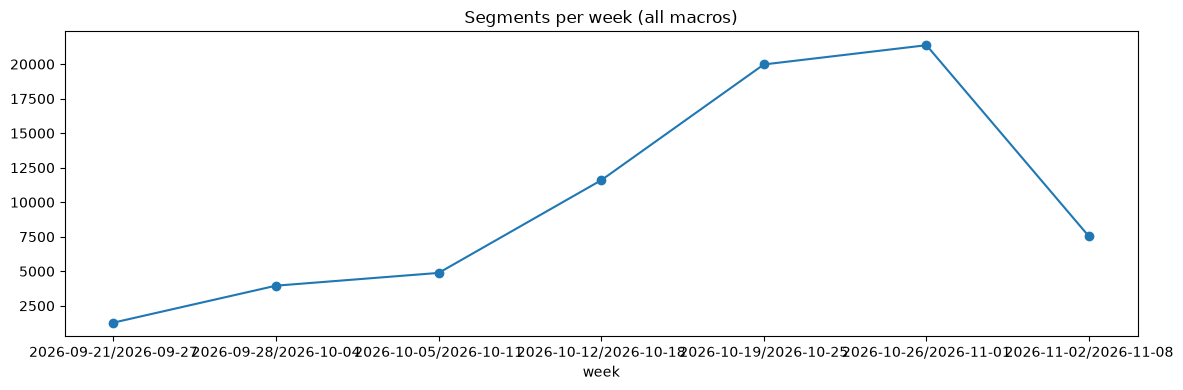

era                                                        before_2026-10-15  \
macro_category            sub_category                                         
documento_di_spesa        preventivo_di_spesa                              6   
                          documento_di_spesa_altro                        10   
denuncia                  richiesta_danni                                139   
documento_di_spesa        fattura                                         73   
denuncia                  cai                                             55   
documentazione_medica     prescrizione_medica                            519   
documento_di_spesa_medica documento_di_spesa_altro                        18   
                          preventivo_di_spesa                             40   
documento_di_spesa        ricevuta_di_pagamento                          107   
documento_di_spesa_medica ricevuta_di_pagamento                          161   
                          scontrino                                      429   
documento_di_spesa        scontrino                                       17   
documento_di_spesa_medica fattura                                       2638   
documentazione_medica     lettera_di_dimissioni                          351   
                          documentazione_medica_altro                   4917   
documento_di_spesa_medica ticket_ssn                                     928   
documentazione_medica     referto_del_pronto_soccorso                   1132   
denuncia                  denuncia_altro                                 888   
documentazione_medica     certificato_avvenuta_guarigione                273   

era                                                        from_2026-10-15  \
macro_category            sub_category                                       
documento_di_spesa        preventivo_di_spesa                          450   
                          documento_di_spesa_altro                     252   
denuncia                  richiesta_danni                             2625   
documento_di_spesa        fattura                                     1308   
denuncia                  cai                                          865   
documentazione_medica     prescrizione_medica                         6339   
documento_di_spesa_medica documento_di_spesa_altro                     164   
                          preventivo_di_spesa                          245   
documento_di_spesa        ricevuta_di_pagamento                        619   
documento_di_spesa_medica ricevuta_di_pagamento                        925   
                          scontrino                                   2267   
documento_di_spesa        scontrino                                     87   
documento_di_spesa_medica fattura                                    13237   
documentazione_medica     lettera_di_dimissioni                       1310   
                          documentazione_medica_altro                17480   
documento_di_spesa_medica ticket_ssn                                  3050   
documentazione_medica     referto_del_pronto_soccorso                 3492   
denuncia                  denuncia_altro                              2430   
documentazione_medica     certificato_avvenuta_guarigione              738   

era                                                        share_from_2026-10-15  
macro_category            sub_category                                            
documento_di_spesa        preventivo_di_spesa                              0.987  
                          documento_di_spesa_altro                         0.962  
denuncia                  richiesta_danni                                  0.950  
documento_di_spesa        fattura                                          0.947  
denuncia                  cai                                              0.940  
documentazione_medica     prescrizione_medica                              0.924  
documento_di_spe

Teacher version not in parquet — interpret drift as collection mix, not model change.


In [65]:
labeled_df["week"] = labeled_df["created_at"].dt.to_period("W").astype(str)
labeled_df["era"] = np.where(labeled_df["created_date"] < pd.Timestamp("2026-10-15", tz="UTC"), "before_2026-10-15", "from_2026-10-15")

weekly = (
    labeled_df.groupby(["week", "macro_category", "sub_category"]).size().unstack(fill_value=0)
)
weekly_total = labeled_df.groupby("week").size()
fig, ax = plt.subplots(figsize=(12, 4))
weekly_total.plot(ax=ax, marker="o")
ax.set_title("Segments per week (all macros)")
plt.tight_layout()
plt.show()

era_share = (
    labeled_df.groupby(["macro_category", "sub_category", "era"]).size().unstack(fill_value=0)
)
era_share["share_from_2026-10-15"] = (
    era_share.get("from_2026-10-15", 0) / (era_share.sum(axis=1).replace(0, np.nan))
).round(3)
o7_era_share = era_share.sort_values("share_from_2026-10-15", ascending=False)
o7_weekly = weekly_total.copy()
display(o7_era_share.head(20))
print("Teacher version not in parquet — interpret drift as collection mix, not model change.")


## Decisioni finali per notebook 00 e PROGETTO.md

In [66]:
decisions = {
    "text_column": TEXT_COLUMN,
    "perimeter_module": "src/slm_baseline/labels.py",
    "segments_in_perimeter": int(len(labeled_df)),
    "empty_text_exclude_eval": int(labeled_df["empty_text"].sum()),
    "out_of_taxonomy_excluded": int(len(out_of_taxonomy)),
    "eda_max_seq_length_sample": int(SELECTED_MAX_SEQ_LENGTH),
    "run_config_max_seq_len": json.load(open(RUN_CONFIG_PATH))["max_seq_len"] if RUN_CONFIG_PATH.is_file() else None,
    "splits_regenerate_if_rows_lt": int(len(labeled_df) * 0.5),
    "tfidf_probe_macro_f1": probe_summary.set_index("macro_category")["macro_f1"].to_dict(),
    "bge_probe_macro_f1": (
        bge_probe_summary.set_index("macro_category")["macro_f1"].to_dict()
        if "bge_probe_summary" in globals() and len(bge_probe_summary)
        else {}
    ),
    "o4_results_dir": str(O4_RESULTS_DIR.resolve()) if O4_RESULTS_DIR.joinpath("config.json").is_file() else None,
    "rare_subs_below_min_train": rare_subs.to_dict(orient="records"),
}
print(json.dumps(decisions, ensure_ascii=False, indent=2))

extras = {}
if "signal_df" in globals() and len(signal_df):
    extras["o3_signal_patterns.csv"] = signal_df
if "sub_summary" in globals():
    extras["o1_sub_summary.csv"] = sub_summary

o6_stats, quasi_by_macro = ensure_o6_artifacts_for_persist()

summary_dir = persist_eda_summary(
    cleanlab_summary=cleanlab_summary,
    cleanlab_issues=cleanlab_issues,
    gold_sketch=gold_sketch,
    o6_stats=o6_stats,
    quasi_by_macro=quasi_by_macro if len(quasi_by_macro) else None,
    o7_weekly=o7_weekly,
    o7_era_share=o7_era_share,
    decisions=decisions,
    extras=extras or None,
)
print("Saved EDA summary:", summary_dir)
display(pd.Series(json.loads((summary_dir / "manifest.json").read_text())["files"], name="artifacts"))


2026-11-05 19:38:18,355 | INFO | __main__ | O6 non eseguito in sessione — ricalcolo statistiche leakage/duplicati


{
  "text_column": "ocr_surrogates",
  "perimeter_module": "src/slm_baseline/labels.py",
  "segments_in_perimeter": 70584,
  "empty_text_exclude_eval": 0,
  "out_of_taxonomy_excluded": 53,
  "eda_max_seq_length_sample": 147456,
  "run_config_max_seq_len": 15360,
  "splits_regenerate_if_rows_lt": 35292,
  "tfidf_probe_macro_f1": {
    "denuncia": 0.953,
    "documentazione_medica": 0.81,
    "documento_di_spesa": 0.796,
    "documento_di_spesa_medica": 0.744
  },
  "bge_probe_macro_f1": {
    "denuncia": 0.931,
    "documentazione_medica": 0.836,
    "documento_di_spesa": 0.734,
    "documento_di_spesa_medica": 0.809
  },
  "o4_results_dir": "/Users/vincenzo_pafundi/Desktop/tesi-magistrale/data/eda_cache/o4",
  "rare_subs_below_min_train": []
}


2026-11-05 19:38:24,072 | INFO | __main__ | O6 quasi-dup non eseguito — ricalcolo riepilogo (può richiedere qualche minuto)
2026-11-05 19:38:39,621 | INFO | __main__ | EDA summary saved under /Users/vincenzo_pafundi/Desktop/tesi-magistrale/data/eda_cache/eda_summary


Saved EDA summary: /Users/vincenzo_pafundi/Desktop/tesi-magistrale/data/eda_cache/eda_summary


0                        config.json
1                     decisions.json
2                 o1_sub_summary.csv
3             o3_signal_patterns.csv
4           o5_cleanlab_by_macro.csv
5                o5_gold_sketch.json
6     o5_suspected_mislabels.parquet
7         o6_leakage_duplicates.json
8          o6_quasi_dup_by_macro.csv
9                   o7_era_share.csv
10            o7_weekly_segments.csv
Name: artifacts, dtype: str